# Quality Control and Preprocessing

In [32]:
# Import modules

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import anndata as ad

In [2]:
# Load data

adata_uc = sc.read_h5ad("data/mmColon_single_cell_85K.h5ad")
print(adata_uc)

AnnData object with n_obs × n_vars = 84612 × 18416
    obs: 'sid', 'n_genes', 'condition', 'batch', 'sample', 'celltype_major', 'celltype_minor', 'celltype_subset'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells'
    uns: 'CCI', 'CCI_sample', 'Celltype_marker_DB', 'DEG', 'DEG_stat', 'GSA_down', 'GSA_up'
    obsm: 'HiCAT_result'


# QC check

To check the quality and the integrity of the dataset, a QC is performed. This step involves the investigation of:

1. UMIs per cell (The entry in X of anndata format)
    A. (Very) Low UMIs could mean ambient RNA is captured, or there are empty droplets. 
    B. (Too) High UMIs could mean 2 cells are captured in 1 droplet. These are called doublets. 
2. Genes detected per cell (Counting Non-zero entries per cell)
    A. Low could mean the cell is of poor-quality
    B. (Unusually) high could mean a doublet might be captured. 

UMIs and genes together show the complexity of the sample. If a sample has high UMIs but only few genes are detected could mean there is some kind of amplification bias or dominant behavior exhibited by the transcript. 

3. % Mitochondrial genes - During stress, cytoplasmic mRNA could leak but the mitochondrial transcript could still remain. Metabolically active cells can have higher % mito. For instance, if a cell is active, it needs energy, so mitochondrial fraction would be up in these cells. It is important to inspect the distribution to see which cells could be impacted by the threshold. 

4. % Ribosomal genes
5. % Haemoglobin genes


In [6]:
# Identify % mito, % ribo and % hemoglobin
adata_uc.var["mt"] = adata_uc.var_names.str.startswith("MT-")
# ribosomal genes
adata_uc.var["ribo"] = adata_uc.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
adata_uc.var["hb"] = adata_uc.var_names.str.contains("^HB[^(P)]")

# Calculate qc metrics
sc.pp.calculate_qc_metrics(adata_uc, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True)


Although the scanpy tutorial mentioned that mito in mice starts with mt-, in this paper it is MT-. Maybe that is how it was processed. 

In [7]:
# Reinspect adata_uc again
print(adata_uc)

AnnData object with n_obs × n_vars = 84612 × 18416
    obs: 'sid', 'n_genes', 'condition', 'batch', 'sample', 'celltype_major', 'celltype_minor', 'celltype_subset', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'CCI', 'CCI_sample', 'Celltype_marker_DB', 'DEG', 'DEG_stat', 'GSA_down', 'GSA_up'
    obsm: 'HiCAT_result'


Now the adata_uc object has metrics added in obs and var

In [ ]:
# Summarize the metrics
print(type(adata_uc.obs))

# adata is a pandas data frame, so to pick the columns, use [[]]
adata_uc.obs[["n_genes_by_counts","total_counts","pct_counts_mt","pct_counts_ribo","pct_counts_hb"]].describe()

<class 'pandas.core.frame.DataFrame'>


,n_genes_by_counts,total_counts,pct_counts_mt,pct_counts_ribo,pct_counts_hb
count,84612.000000,84612.000000,84612.000000,84612.000000,84612.000000
mean,1931.992424,7409.290527,6.358524,19.912085,0.025477
std,1233.752926,8149.110352,10.198373,11.360708,0.834893
min,200.000000,407.000000,0.000000,0.299065,0.000000
25%,1108.000000,2958.000000,2.201895,10.499398,0.000000
50%,1593.000000,4886.500000,3.318221,18.410825,0.000000
75%,2615.000000,8988.250000,5.284570,29.144129,0.010400
max,9105.000000,167951.000000,95.278099,59.881424,82.859909


In the summary, minimum genes per cell is 200, it could mean that a minimum filter was applied by the authors (However, it is not mentioned in the paper, so it could also mean that in this experiment, there were no samples with detected genes below 200 --> brings to next exploration). Minimum gene counts is 407 which means there are cells with less than 500 genes. 

In [24]:
# Per sample, investigate summary and write it in a csv
stat_per_sample = adata_uc.obs.groupby("sample")[["n_genes_by_counts","total_counts","pct_counts_mt","pct_counts_ribo","pct_counts_hb"]].describe()
stat_per_sample.to_csv("stat_per_sample.csv")


C:\Users\shab3\AppData\Local\Temp\ipykernel_26184\1963798641.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stat_per_sample = adata_uc.obs.groupby("sample")[["n_genes_by_counts","total_counts","pct_counts_mt","pct_counts_ribo","pct_counts_hb"]].describe()


Per sample metrics also show that the number of detected genes start from 200 in all the samples. 

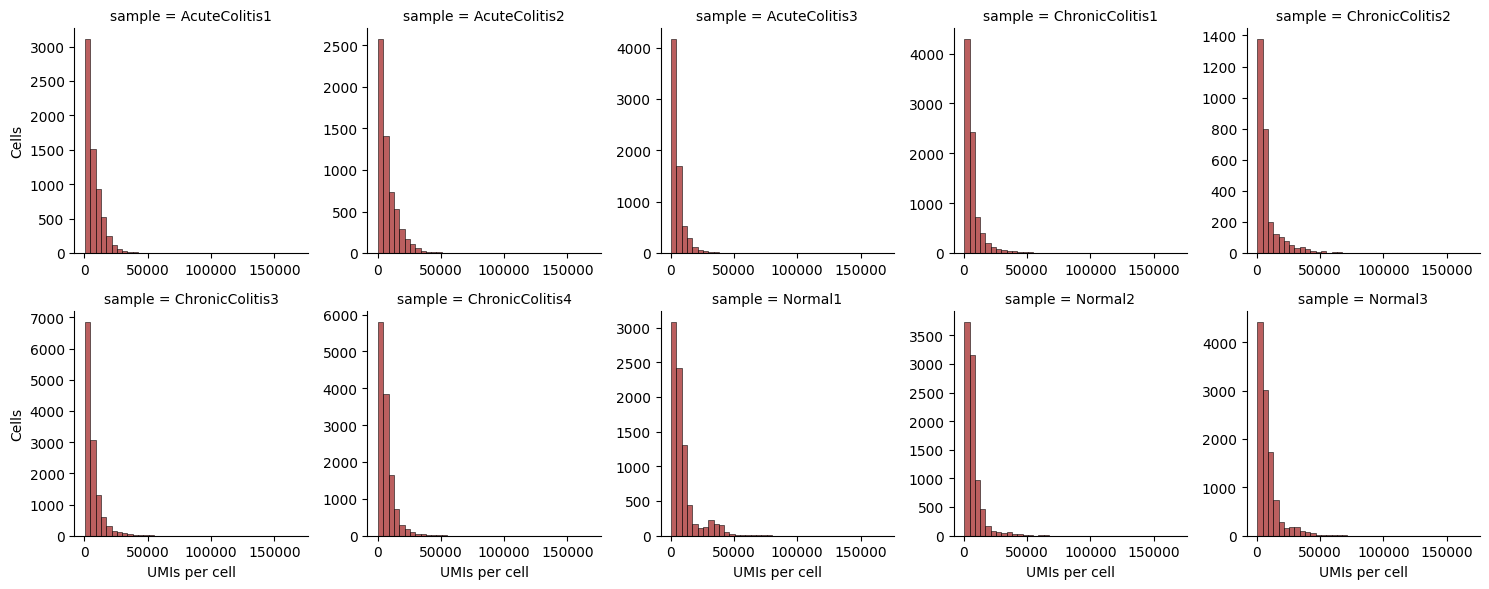

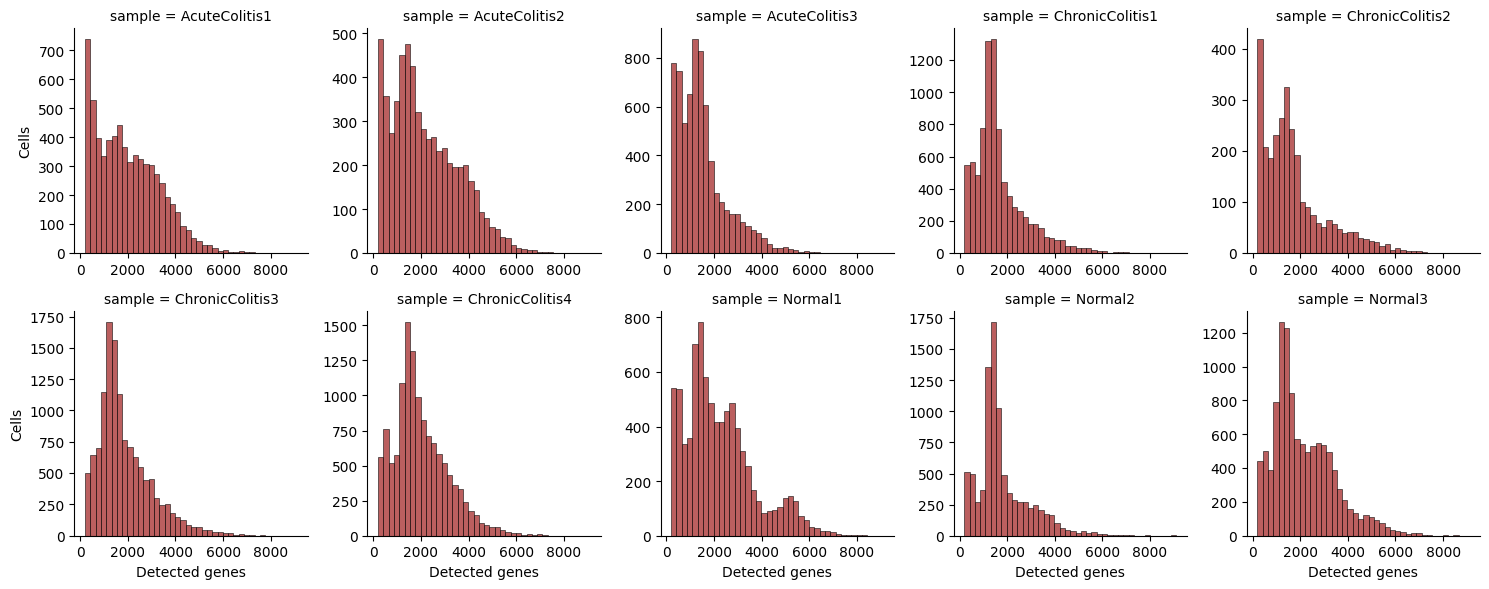

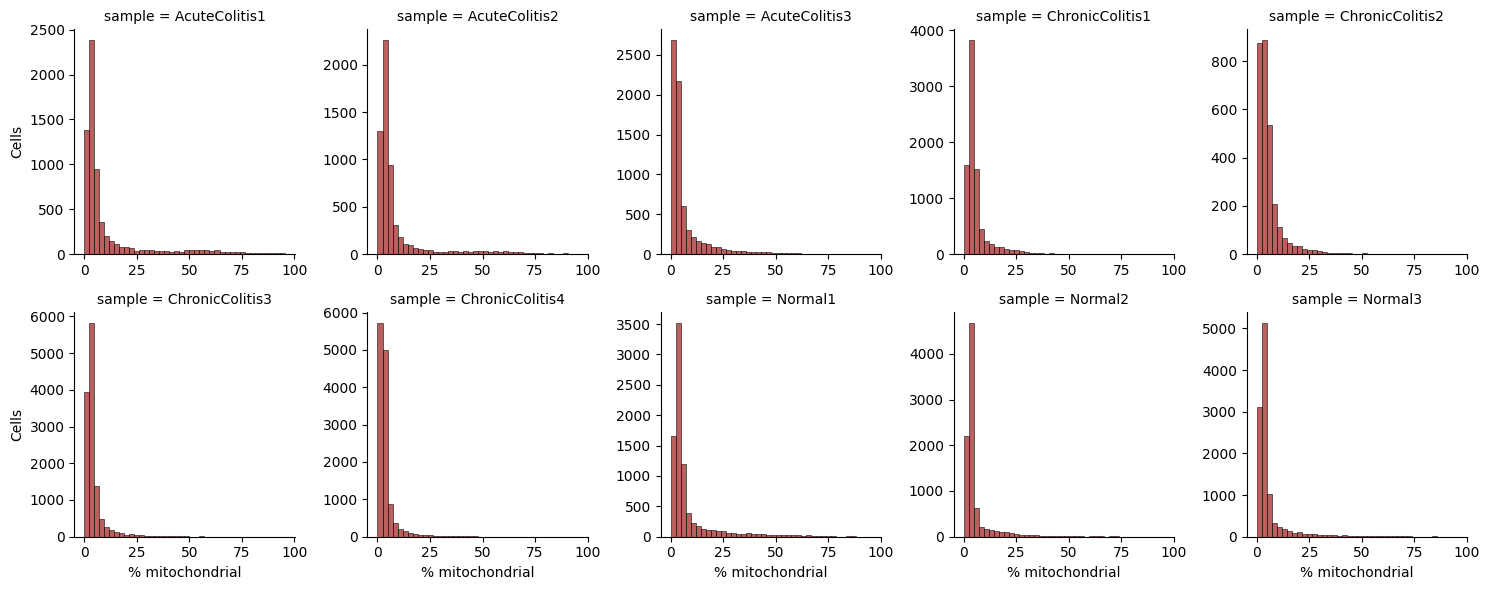

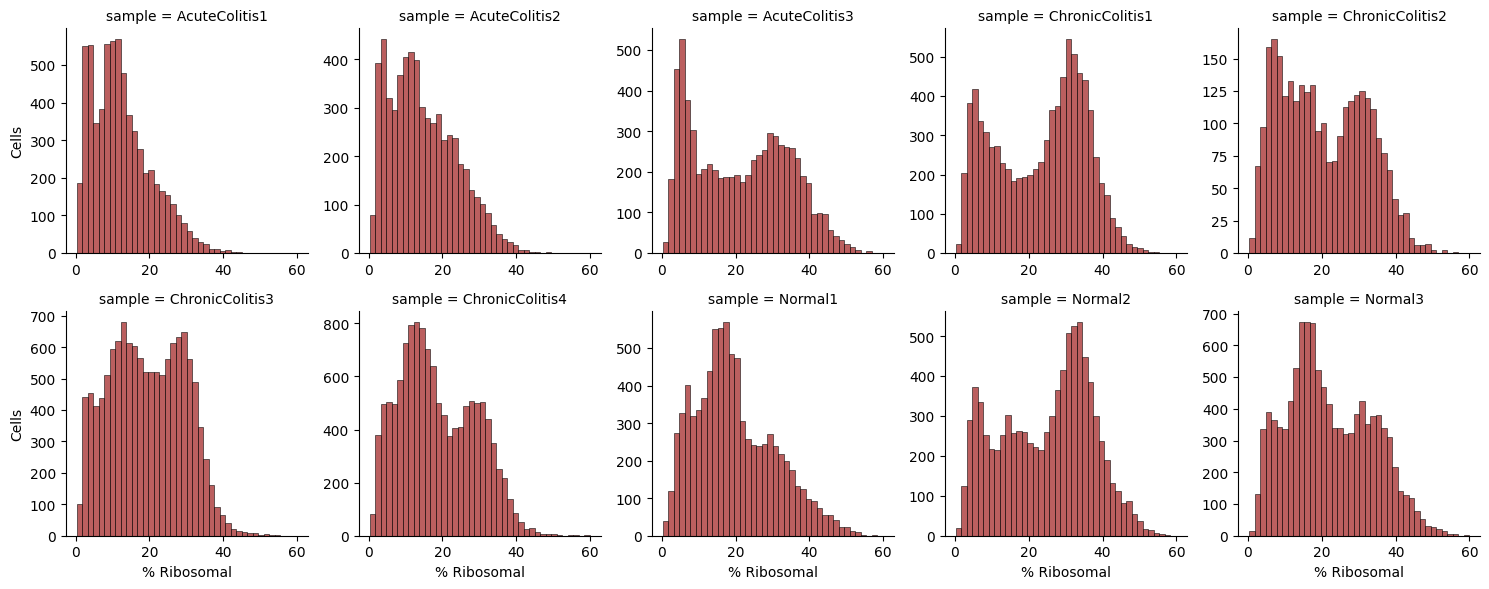

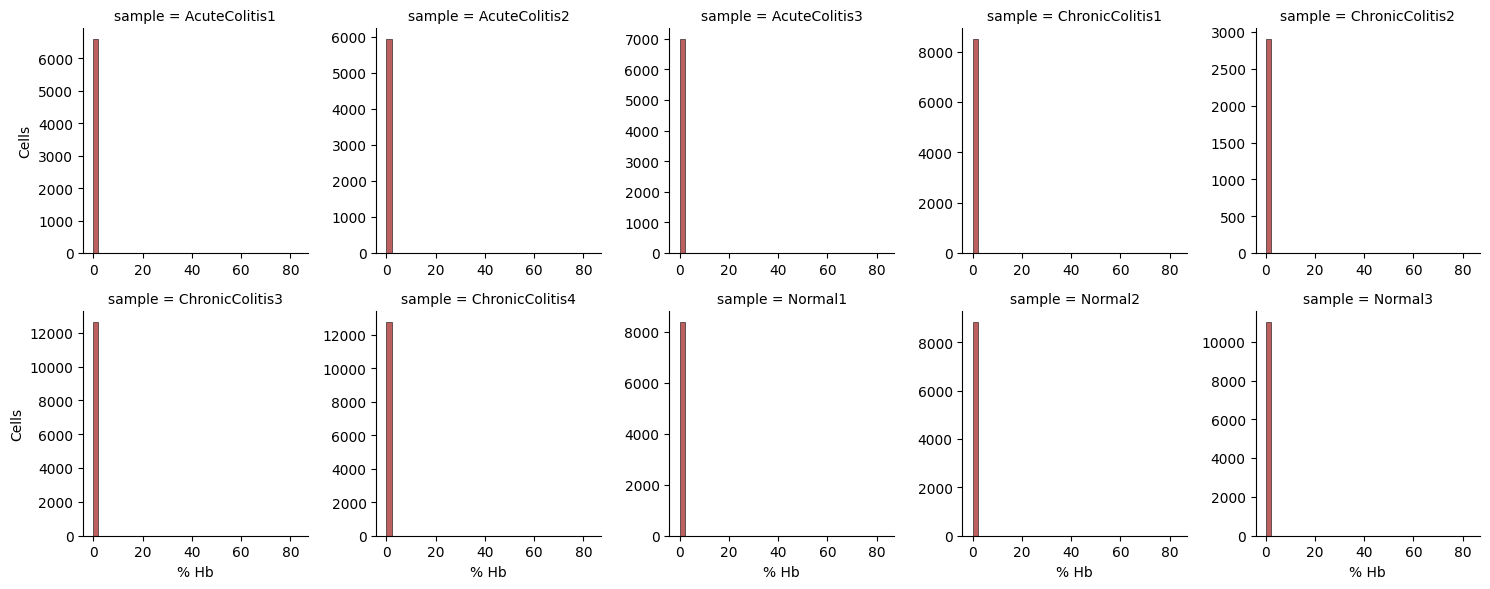

In [50]:
# Visualize distribution per sample for each of the metrics with histograms

# Make a dictionary so it is easy

qc_metrics = {"total_counts": "UMIs per cell", "n_genes_by_counts": "Detected genes", "pct_counts_mt": "% mitochondrial", "pct_counts_ribo": "% Ribosomal", "pct_counts_hb": "% Hb"}

for col, label in qc_metrics.items():
    histogram = sns.displot(data=adata_uc.obs, x=col, col="sample", col_wrap=5, bins=40, height=3, color = "brown", facet_kws={"sharey": False, "sharex": False})
    histogram.set_axis_labels(label, "Cells")

Looking at histogram valleys. The histogram for UMIs per cell for all the samples is right skewed. Sample Normal 1 catches attention. There is a cell population that has much higher RNA content, and this is not observed in diseased samples. But why does Normal 2 and 3 don't have that? Next question: How do samples differ from each other? They are triplicates and used to measure inter individual variability. So it could just be that? 

Additionally, UMI's for all samples range from around 400 to 120,000. In this case, to visualize better, do a log scale visualization so that you visualize in ratios. It just changes the way the data is visualized. 

In [35]:
print(adata_uc)

AnnData object with n_obs × n_vars = 84612 × 18416
    obs: 'sid', 'n_genes', 'condition', 'batch', 'sample', 'celltype_major', 'celltype_minor', 'celltype_subset', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'CCI', 'CCI_sample', 'Celltype_marker_DB', 'DEG', 'DEG_stat', 'GSA_down', 'GSA_up'
    obsm: 'HiCAT_result'


In [46]:
adata_uc.obs.groupby("condition")[["sid"]].describe()

C:\Users\shab3\AppData\Local\Temp\ipykernel_26184\3697655110.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata_uc.obs.groupby("condition")[["sid"]].describe()


sid                               
                count unique              top   freq
condition                                           
AcuteColitis    19514      3    AcuteColitis3   6981
ChronicColitis  36827      4  ChronicColitis4  12769
Healthy         28271      3          Normal3  11032

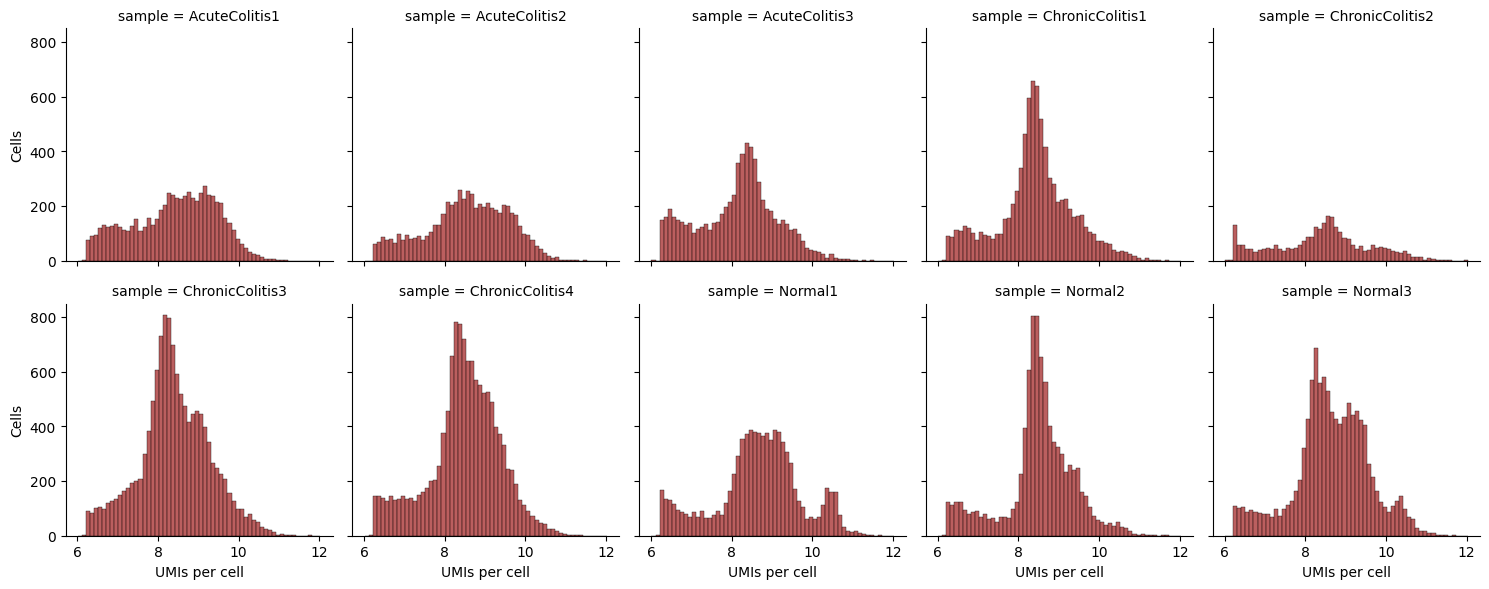

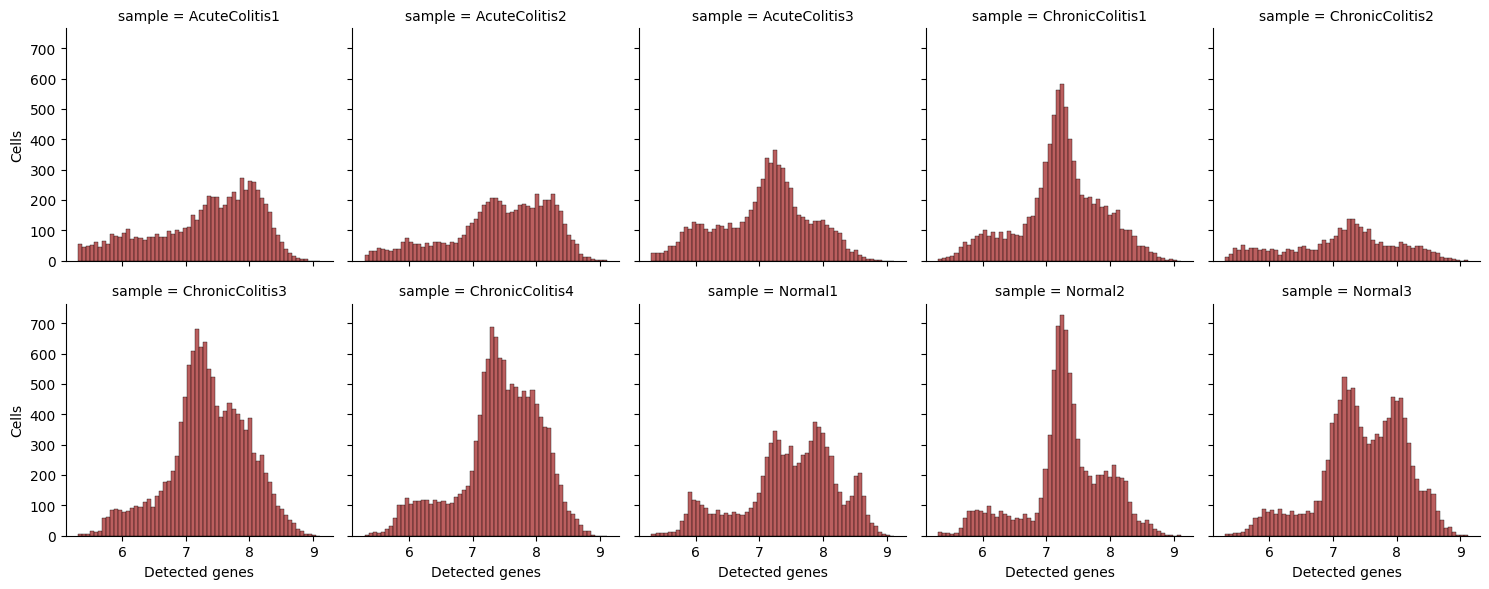

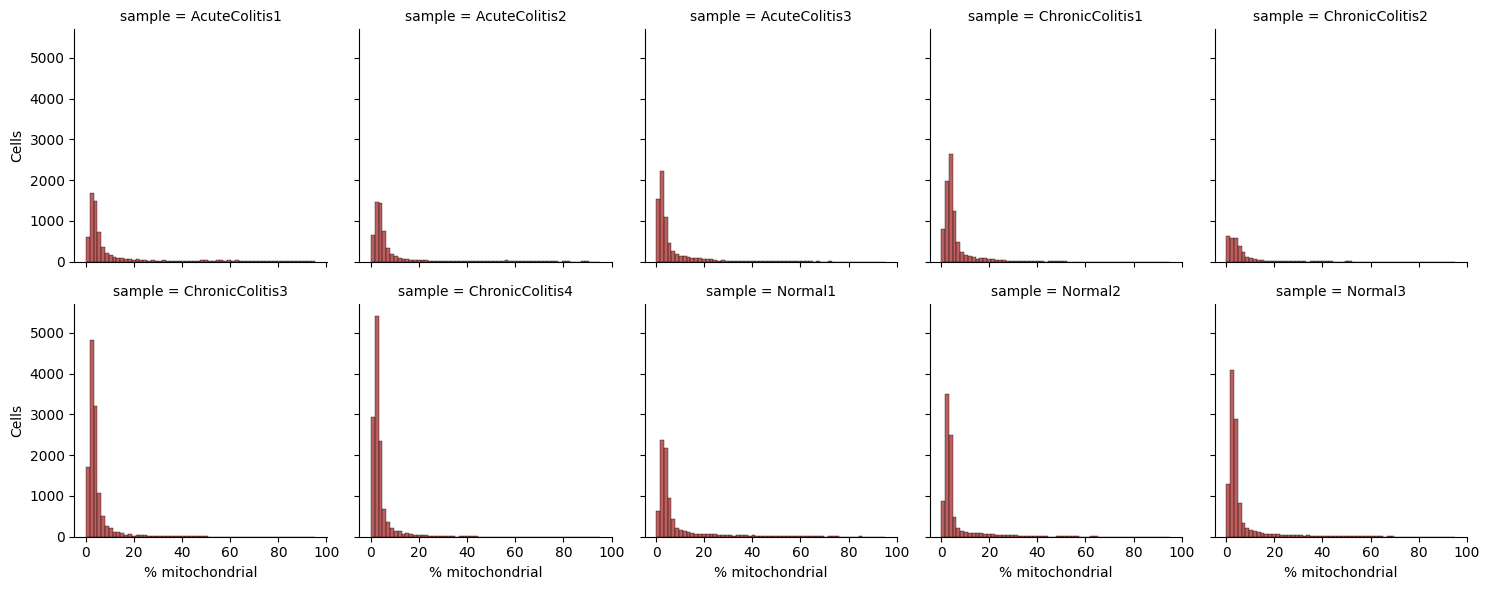

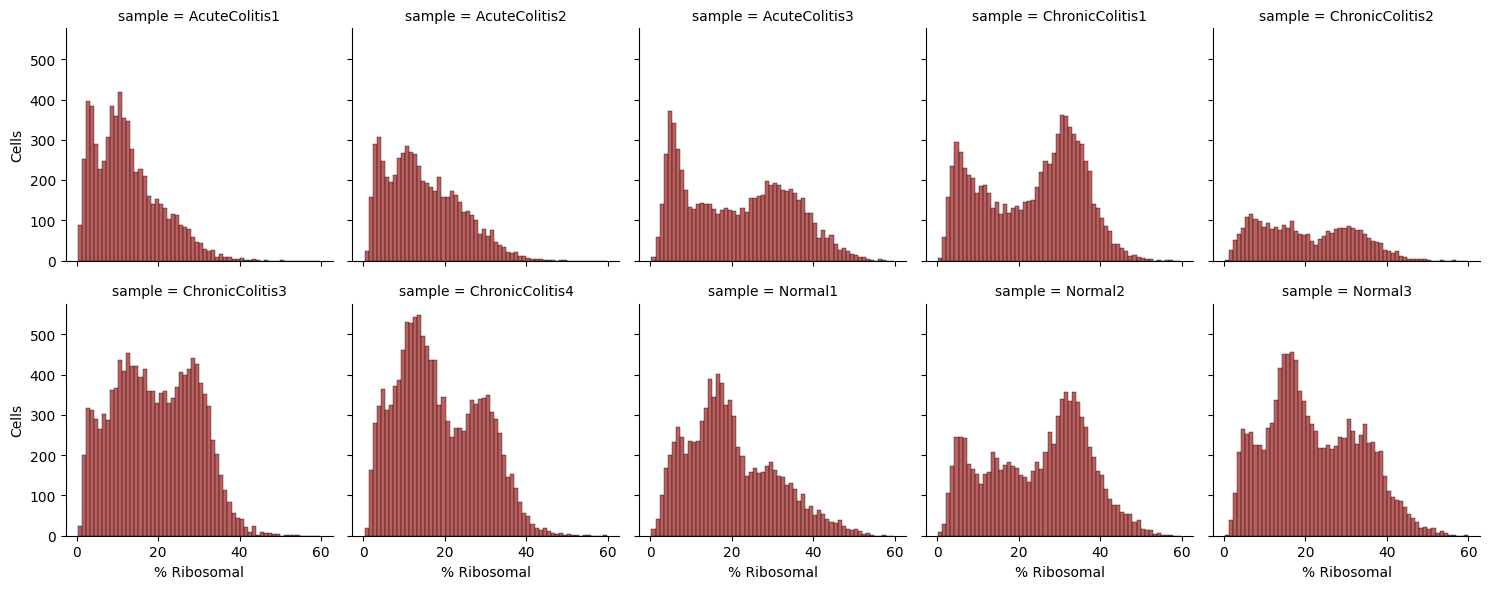

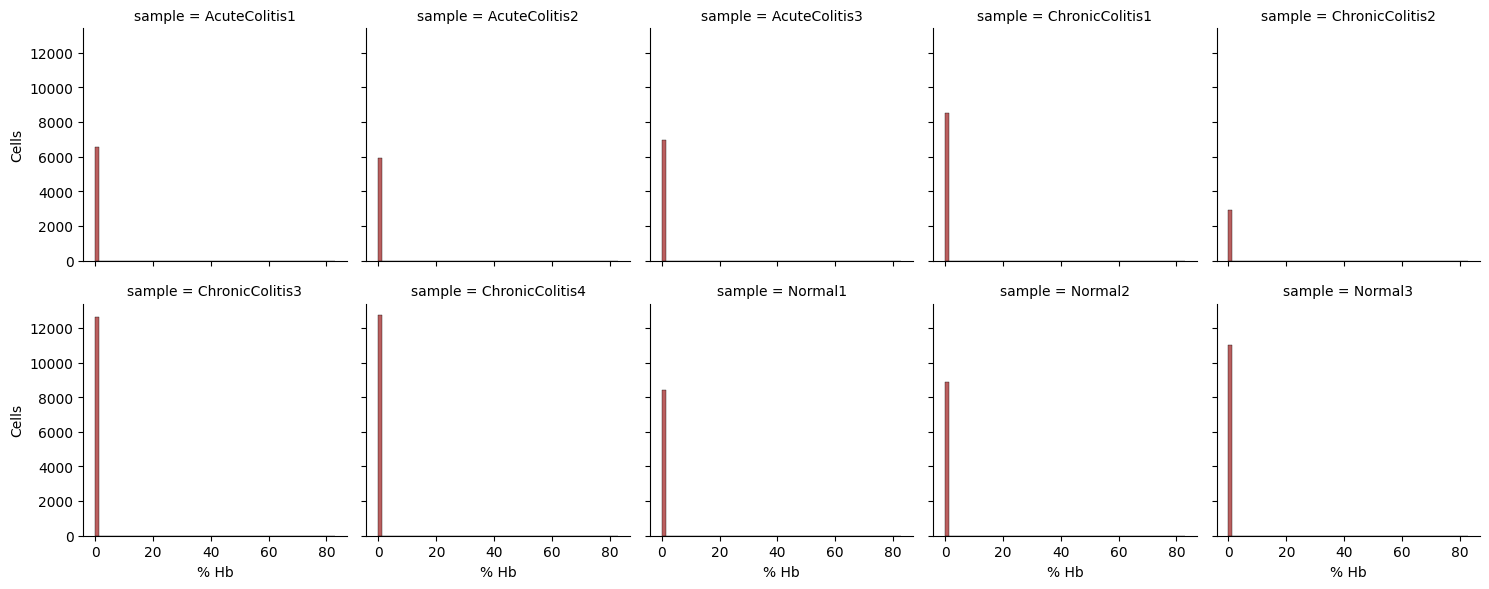

In [53]:
# How do these histograms look when the data is log transformed
qc_metrics_log = {"log1p_total_counts": "UMIs per cell", "log1p_n_genes_by_counts": "Detected genes", "pct_counts_mt": "% mitochondrial", "pct_counts_ribo": "% Ribosomal", "pct_counts_hb": "% Hb"}

for col, label in qc_metrics_log.items():
    histogram = sns.displot(data=adata_uc.obs, x=col, col="sample", col_wrap=5, bins=60, height=3, color = "brown", facet_kws={"sharey": True, "sharex": True})
    histogram.set_axis_labels(label, "Cells")

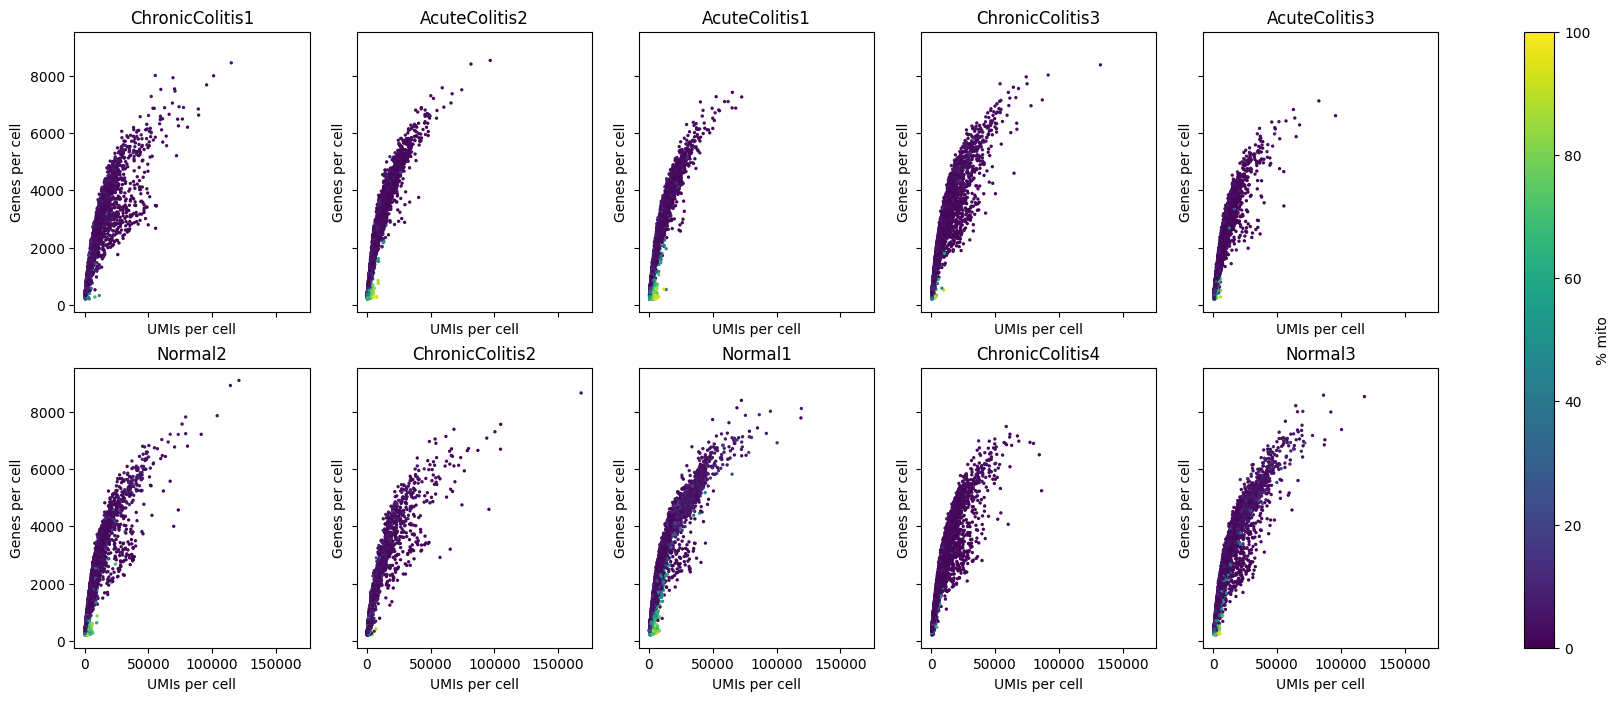

In [54]:
# Use scatter plots to visualize UMI vs genes per cell colored by mitochondrial percentage

adata_uc_samples = adata_uc.obs["sample"].unique()
fig, axes = plt.subplots(2, 5, figsize=(22, 8), sharex=True, sharey=True)

for ax, s in zip(axes.flat, adata_uc_samples):
    d = adata_uc.obs[adata_uc.obs["sample"] == s]
    sc_plot = ax.scatter(d["total_counts"], d["n_genes_by_counts"], c=d["pct_counts_mt"], s=2, cmap="viridis", vmax=100)
    #ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(s)
    ax.set_xlabel("UMIs per cell"); ax.set_ylabel("Genes per cell")

fig.colorbar(sc_plot, ax=axes, label="% mito")
plt.show()

In [ ]:
# % Mito - What happens if 15% threshold is applied
adata_uc.obs["high_mito"] = adata_uc.obs["pct_counts_mt"] > 15
print(adata_uc.obs.columns.tolist())

sample = adata_uc.obs.groupby("sample")
# Is there a specific type of cell that would be majorly impacted?
celltype = "celltype_major" 
print(pd.crosstab(adata_uc.obs[celltype], adata_uc.obs["high_mito"], normalize="index").round(3))

# Per sample, what are the tissues that will be affected? 

['sid', 'n_genes', 'condition', 'batch', 'sample', 'celltype_major', 'celltype_minor', 'celltype_subset', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'high_mito']
high_mito           False  True 
celltype_major                  
B cell              0.940  0.060
Endothelial cell    0.961  0.039
Epithelial cell     0.585  0.415
Fibroblast          0.900  0.100
Myeloid cell        0.932  0.068
Smooth muscle cell  0.880  0.120
T cell              0.935  0.065


C:\Users\shab3\AppData\Local\Temp\ipykernel_26184\733411141.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample = adata_uc.obs.groupby("sample")


TypeError: unhashable type: 'DataFrame'

In [63]:
df = adata_uc.obs[["sample", celltype, "high_mito"]].copy()
df["high_mito"] = df["high_mito"].astype(bool)

# Fraction of high-mito cells: rows = cell type, columns = sample
frac = df.groupby([celltype, "sample"], observed=True)["high_mito"].mean().unstack()
print(frac.round(3))

# Cell counts per group, so you can see which fractions are based on few cells
n = df.groupby([celltype, "sample"], observed=True).size().unstack()
print(n)

sample              AcuteColitis1  AcuteColitis2  AcuteColitis3  \
celltype_major                                                    
B cell                      0.069          0.052          0.127   
Endothelial cell            0.046          0.030          0.101   
Epithelial cell             0.870          0.870          0.464   
Fibroblast                  0.281          0.273          0.177   
Myeloid cell                0.166          0.151          0.089   
Smooth muscle cell          0.113          0.101          0.210   
T cell                      0.097          0.077          0.077   

sample              ChronicColitis1  ChronicColitis2  ChronicColitis3  \
celltype_major                                                          
B cell                        0.071            0.069            0.022   
Endothelial cell              0.020            0.045            0.042   
Epithelial cell               0.364            0.200            0.353   
Fibroblast                    0

Epithelial cells is expected, as this is colon tissue and dissociation of colon tissue could result in high % mito. But is it really technical or has some biology?

In [ ]:
# Low UMI and Low genes have to be removed - How to set threshold?



In [ ]:
# Doublet detection

In [ ]:
# Applying initial filtering thresholds and inspecting diagnostics

## Preprocessing

In [ ]:
# Normalization

In [ ]:
# Feature selection and Dimensionality reduction

In [ ]:
# Leiden clustering